<a href="https://colab.research.google.com/github/bayan-Alharbi/adhd-app/blob/main/EEG_ADHD_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EEG ADHD Dataset - Exploratory Data Analysis (EDA)
**Dataset:** Mendeley EEG ADHD GCPDS  

## Step 1 - Download Dataset from Kaggle

In [ ]:
!pip install kaggle -q

from google.colab import files
print('Upload your kaggle.json file:')
uploaded = files.upload()

import os
os.makedirs('/root/.kaggle', exist_ok=True)
os.rename('/content/kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

!kaggle datasets download -d andreslopezb/mendeley-data-eeg-adhd-gcpds --unzip -p /content/dataset
print('Dataset downloaded successfully!')

Upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/andreslopezb/mendeley-data-eeg-adhd-gcpds
License(s): CC-BY-SA-4.0
100% 50.1M/50.1M [00:00<00:00, 69.5MB/s]

Dataset downloaded successfully!


## Step 2 - Import Libraries & Load Data

In [ ]:
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import ttest_ind
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

# Load .mat files
MADHD_raw = scipy.io.loadmat('/content/dataset/MENDELEY_DATA_EEG_ADHD_GCPDS/MADHD.mat')
FADHD_raw = scipy.io.loadmat('/content/dataset/MENDELEY_DATA_EEG_ADHD_GCPDS/FADHD.mat')
MC_raw    = scipy.io.loadmat('/content/dataset/MENDELEY_DATA_EEG_ADHD_GCPDS/MC.mat')
FC_raw    = scipy.io.loadmat('/content/dataset/MENDELEY_DATA_EEG_ADHD_GCPDS/FC.mat')

# Extract first session for each group
MADHD_data = MADHD_raw['MADHD'][0][0]   # (27, 7680, 2)
FADHD_data = FADHD_raw['FADHD'][0][0]   # (11, 7680, 2)
MC_data    = MC_raw['MC'][0][0]          # (29, 7680, 2)
FC_data    = FC_raw['FC'][0][0]          # (13, 7680, 2)

FS = 128  # Sampling frequency (Hz)

datasets_clean = {'MADHD': MADHD_data, 'FADHD': FADHD_data, 'MC': MC_data, 'FC': FC_data}
labels  = {'MADHD': 'ADHD',    'FADHD': 'ADHD',    'MC': 'Control', 'FC': 'Control'}
genders = {'MADHD': 'Male',    'FADHD': 'Female',   'MC': 'Male',    'FC': 'Female'}
colors  = {'MADHD': '#E74C3C', 'FADHD': '#E67E22',  'MC': '#2980B9', 'FC': '#27AE60'}

print('Data loaded successfully')
for name, data in datasets_clean.items():
    print(f'   {name}: {data.shape}  -> (subjects, samples, channels)')

Data loaded successfully
   MADHD: (27, 7680, 2)  -> (subjects, samples, channels)
   FADHD: (11, 7680, 2)  -> (subjects, samples, channels)
   MC: (29, 7680, 2)  -> (subjects, samples, channels)
   FC: (13, 7680, 2)  -> (subjects, samples, channels)


## Step 3 - Basic Statistics & Data Overview

In [ ]:
print('=' * 65)
print('         Basic Statistics & Data Overview')
print('=' * 65)

for name, data in datasets_clean.items():
    n_subjects, n_samples, n_channels = data.shape
    duration_sec = n_samples / FS
    print(f'\n{name}  [{labels[name]} - {genders[name]}]')
    print(f'   Subjects   : {n_subjects}')
    print(f'   Channels   : {n_channels}')
    print(f'   Samples    : {n_samples}')
    print(f'   Duration   : {duration_sec:.1f} sec ({duration_sec/60:.2f} min)')
    print(f'   Mean + STD : {np.mean(data):.4f} +/- {np.std(data):.4f} uV')
    print(f'   Min / Max  : {np.min(data):.4f} / {np.max(data):.4f} uV')

print('\n' + '=' * 65)
print(f'  Total ADHD    : {MADHD_data.shape[0] + FADHD_data.shape[0]} subjects')
print(f'  Total Control : {MC_data.shape[0] + FC_data.shape[0]} subjects')
print(f'  Total Overall : {sum(d.shape[0] for d in datasets_clean.values())} subjects')
print('=' * 65)

         Basic Statistics & Data Overview

MADHD  [ADHD - Male]
   Subjects   : 27
   Channels   : 2
   Samples    : 7680
   Duration   : 60.0 sec (1.00 min)
   Mean + STD : -0.3535 +/- 37.4684 uV
   Min / Max  : -506.8280 / 517.5250 uV

FADHD  [ADHD - Female]
   Subjects   : 11
   Channels   : 2
   Samples    : 7680
   Duration   : 60.0 sec (1.00 min)
   Mean + STD : 0.0763 +/- 15.9687 uV
   Min / Max  : -366.9300 / 327.4300 uV

MC  [Control - Male]
   Subjects   : 29
   Channels   : 2
   Samples    : 7680
   Duration   : 60.0 sec (1.00 min)
   Mean + STD : -0.4180 +/- 12.0047 uV
   Min / Max  : -342.6240 / 362.3630 uV

FC  [Control - Female]
   Subjects   : 13
   Channels   : 2
   Samples    : 7680
   Duration   : 60.0 sec (1.00 min)
   Mean + STD : 1.1390 +/- 13.4808 uV
   Min / Max  : -344.5550 / 274.9470 uV

  Total ADHD    : 38 subjects
  Total Control : 42 subjects
  Total Overall : 80 subjects


## Step 4 - Raw EEG Signals Visualization

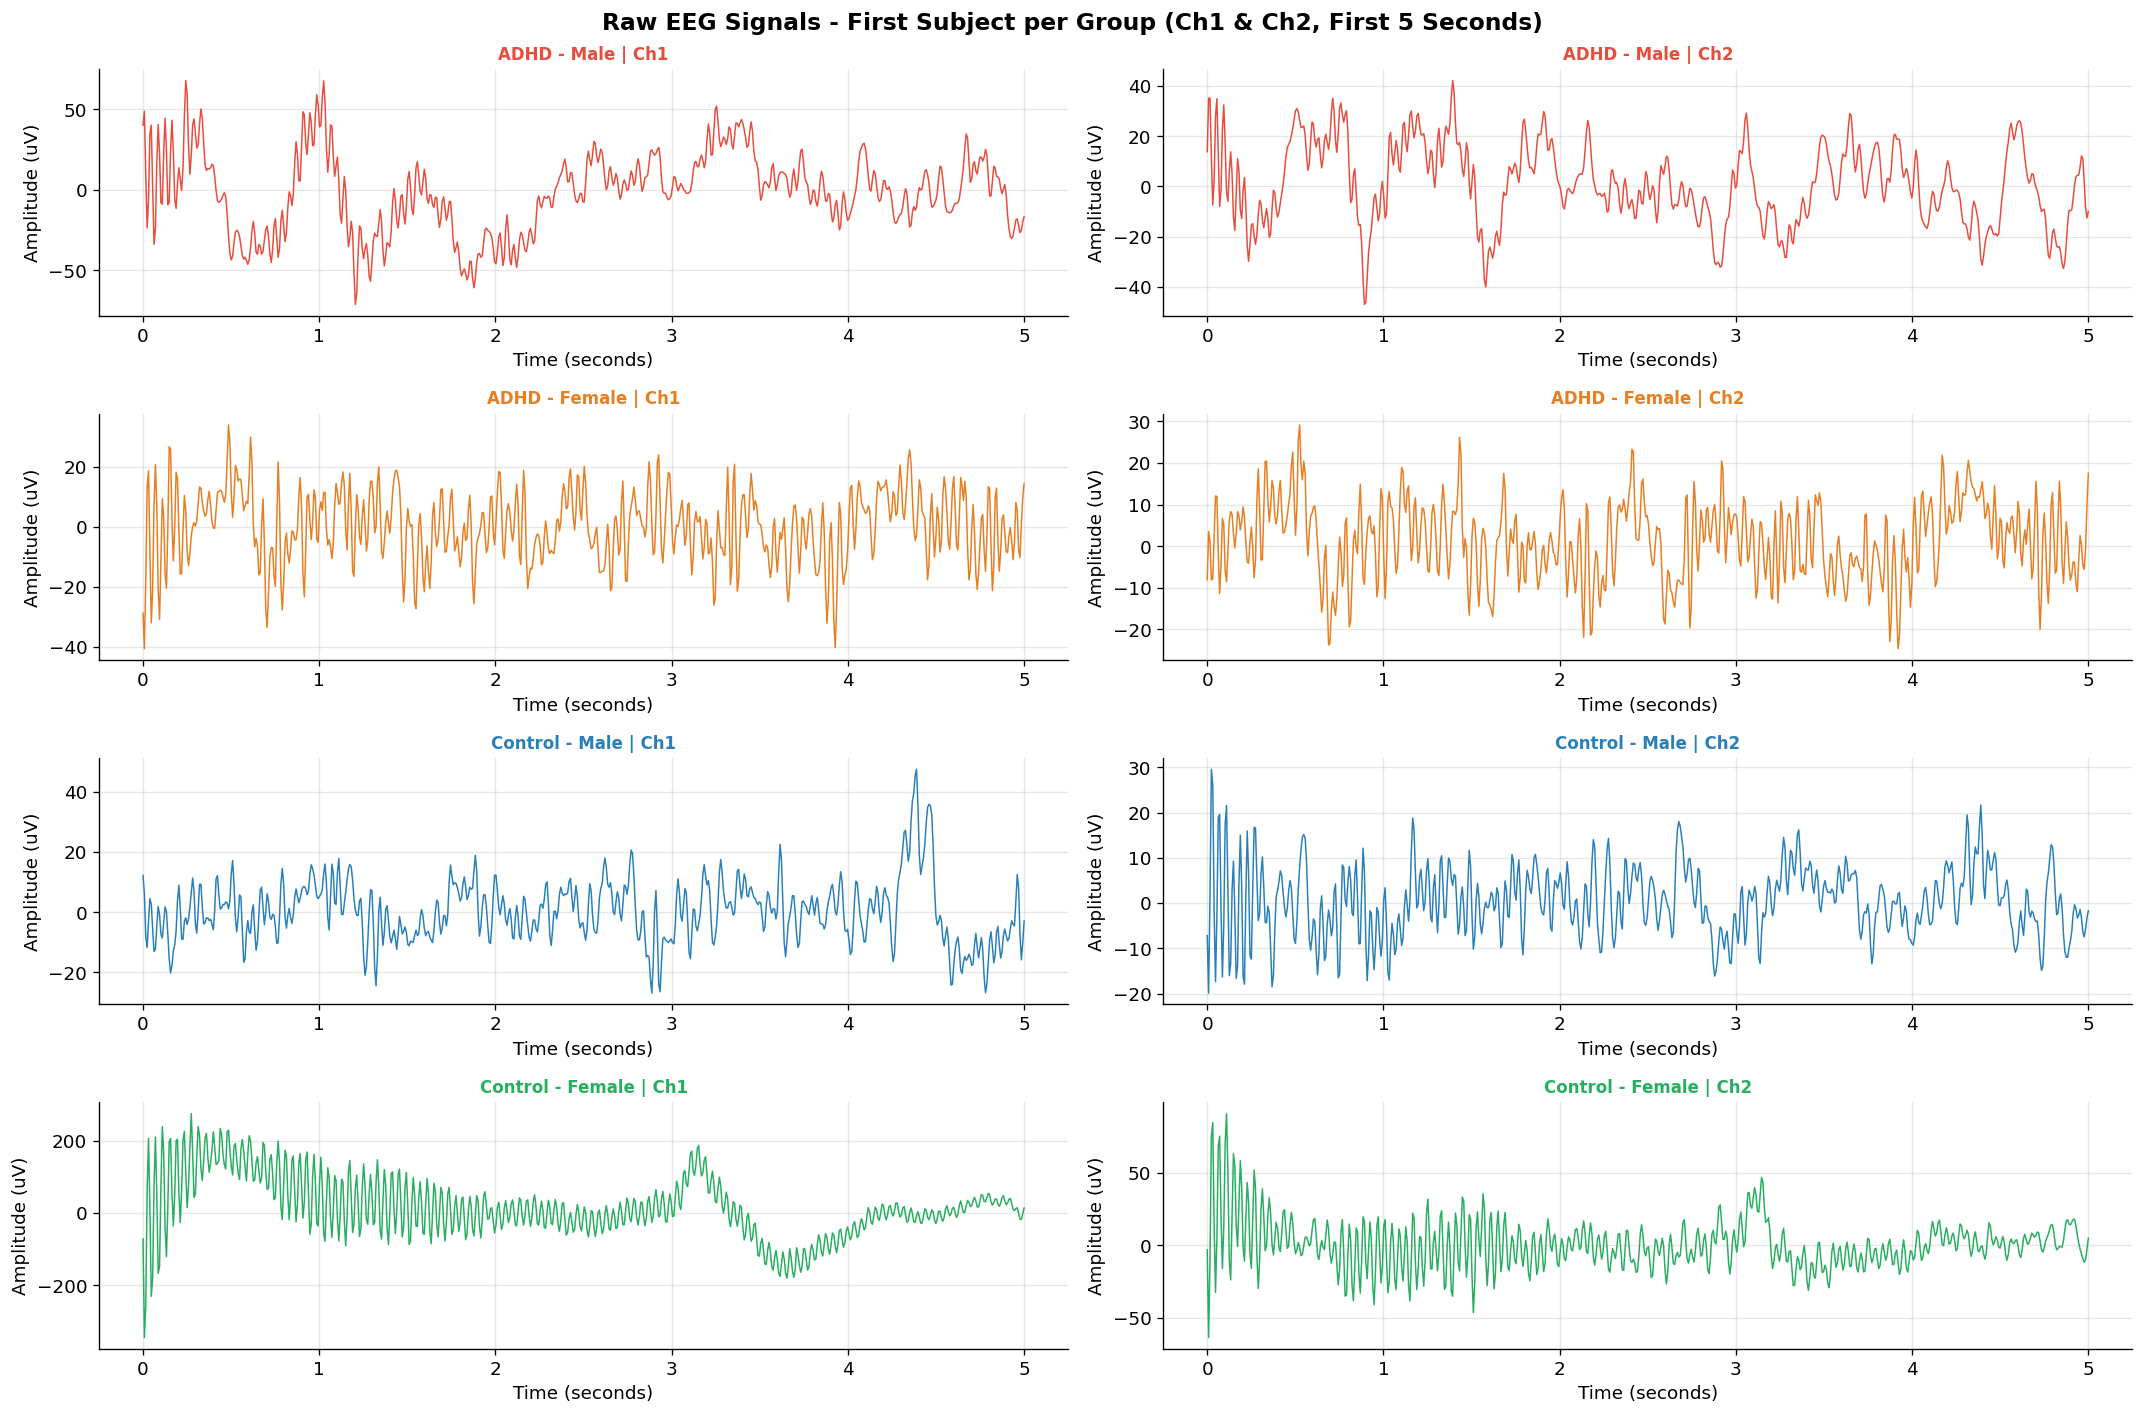

Saved: raw_eeg_signals.png


In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(18, 12))
fig.suptitle('Raw EEG Signals - First Subject per Group (Ch1 & Ch2, First 5 Seconds)',
             fontsize=14, fontweight='bold')

groups = [
    ('MADHD', MADHD_data, '#E74C3C', 'ADHD - Male'),
    ('FADHD', FADHD_data, '#E67E22', 'ADHD - Female'),
    ('MC',    MC_data,    '#2980B9', 'Control - Male'),
    ('FC',    FC_data,    '#27AE60', 'Control - Female'),
]

n_plot    = FS * 5
time_axis = np.linspace(0, 5, n_plot)

for row, (name, data, color, title) in enumerate(groups):
    subj = data[0]
    for ch in range(2):
        ax = axes[row][ch]
        ax.plot(time_axis, subj[:n_plot, ch], color=color, linewidth=0.9)
        ax.set_title(f'{title} | Ch{ch+1}', color=color, fontweight='bold', fontsize=10)
        ax.set_xlabel('Time (seconds)')
        ax.set_ylabel('Amplitude (uV)')
        ax.grid(True, alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('raw_eeg_signals.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: raw_eeg_signals.png')

## Step 5 - Power Spectral Density (PSD)

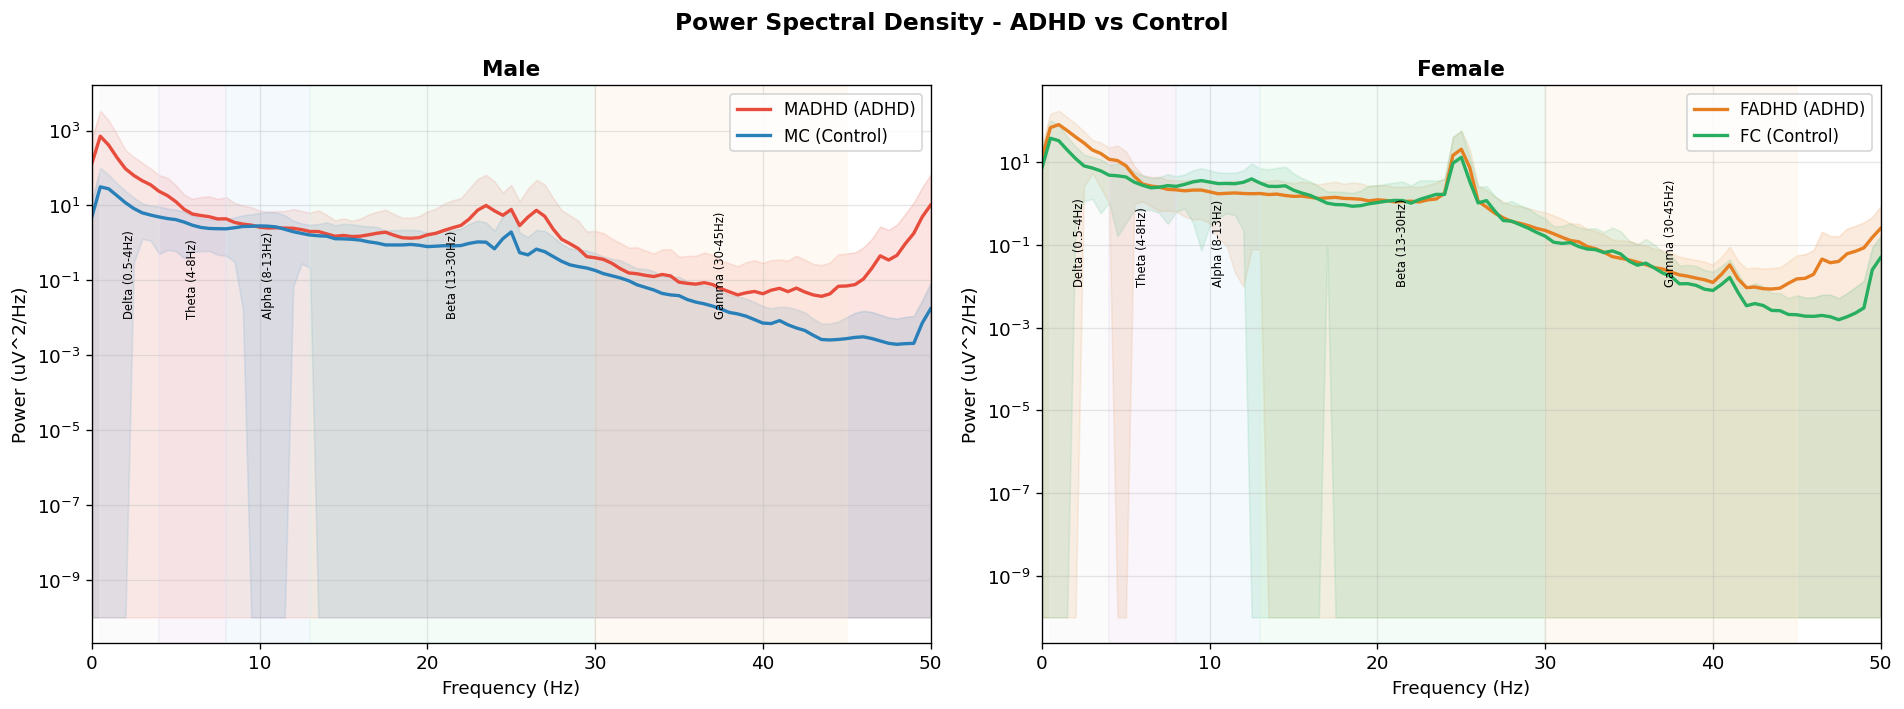

Saved: psd_comparison.png


In [ ]:
bands = {
    'Delta (0.5-4Hz)': (0.5, 4),
    'Theta (4-8Hz)':   (4,   8),
    'Alpha (8-13Hz)':  (8,  13),
    'Beta (13-30Hz)':  (13, 30),
    'Gamma (30-45Hz)': (30, 45),
}

def compute_avg_psd(data, fs=128):
    all_psds = []
    for subj in data:
        for ch in range(subj.shape[1]):
            freqs, psd = signal.welch(subj[:, ch], fs=fs, nperseg=fs*2)
            all_psds.append(psd)
    return freqs, np.mean(all_psds, axis=0), np.std(all_psds, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Power Spectral Density - ADHD vs Control', fontsize=14, fontweight='bold')

band_bg_colors = ['#F0F3F4', '#E8DAEF', '#D6EAF8', '#D5F5E3', '#FDEBD0']

for ax, title, grp_adhd, grp_ctrl, c_adhd, c_ctrl, lbl_adhd, lbl_ctrl in [
    (axes[0], 'Male',   MADHD_data, MC_data,   '#E74C3C', '#2980B9', 'MADHD (ADHD)', 'MC (Control)'),
    (axes[1], 'Female', FADHD_data, FC_data,   '#E67E22', '#27AE60', 'FADHD (ADHD)', 'FC (Control)'),
]:
    for data, color, label in [(grp_adhd, c_adhd, lbl_adhd), (grp_ctrl, c_ctrl, lbl_ctrl)]:
        freqs, mean_psd, std_psd = compute_avg_psd(data)
        mask = freqs <= 50
        ax.semilogy(freqs[mask], mean_psd[mask], color=color, linewidth=2, label=label)
        ax.fill_between(freqs[mask],
                        np.maximum(mean_psd[mask]-std_psd[mask], 1e-10),
                        mean_psd[mask]+std_psd[mask],
                        color=color, alpha=0.15)

    for (bname, (flo, fhi)), bc in zip(bands.items(), band_bg_colors):
        ax.axvspan(flo, fhi, alpha=0.25, color=bc)
        ax.text((flo+fhi)/2, 1e-2, bname, ha='center', fontsize=7, va='bottom', rotation=90)

    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power (uV^2/Hz)')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, which='both')
    ax.set_xlim(0, 50)

plt.tight_layout()
plt.savefig('psd_comparison.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: psd_comparison.png')

## Step 6 - Band Power Comparison & t-test

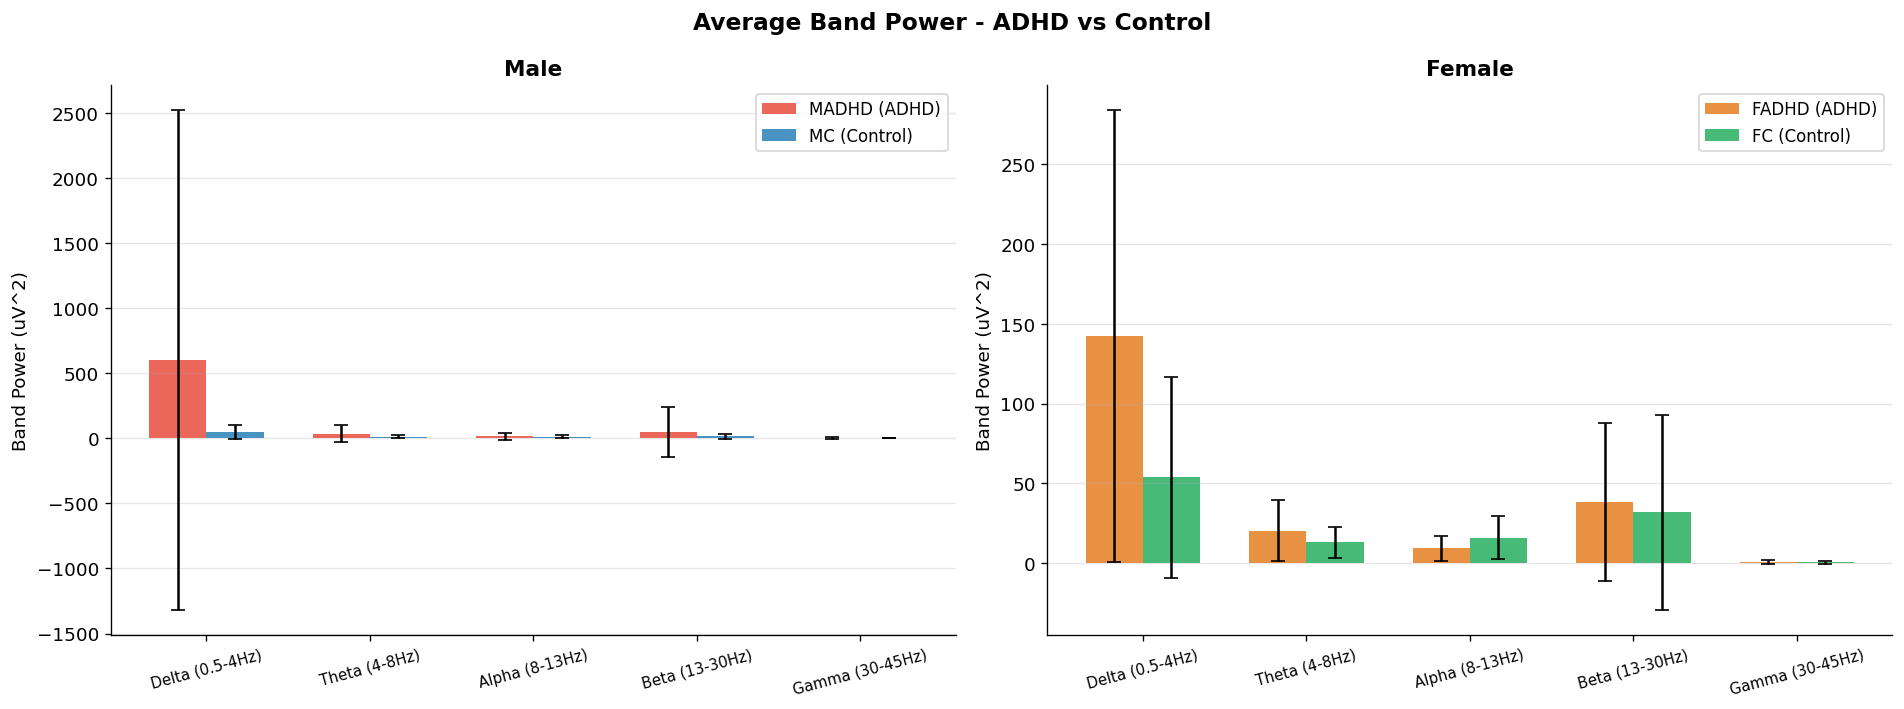

  t-test Results - ADHD vs Control
Band                   Group      p-value      Significant?
------------------------------------------------------------
Delta (0.5-4Hz)        Male       0.0322       Yes (p<0.05)
Delta (0.5-4Hz)        Female     0.0074       Yes (p<0.05)
Theta (4-8Hz)          Male       0.0115       Yes (p<0.05)
Theta (4-8Hz)          Female     0.1050       No
Alpha (8-13Hz)         Male       0.6943       No
Alpha (8-13Hz)         Female     0.0481       Yes (p<0.05)
Beta (13-30Hz)         Male       0.1675       No
Beta (13-30Hz)         Female     0.6837       No
Gamma (30-45Hz)        Male       0.2791       No
Gamma (30-45Hz)        Female     0.6689       No


In [ ]:
def band_power(psd, freqs, flo, fhi):
    idx = np.where((freqs >= flo) & (freqs <= fhi))[0]
    return np.trapz(psd[idx], freqs[idx])

def get_band_powers(data, fs=128):
    results = {b: [] for b in bands}
    for subj in data:
        for ch in range(subj.shape[1]):
            freqs, psd = signal.welch(subj[:, ch], fs=fs, nperseg=fs*2)
            for bname, (flo, fhi) in bands.items():
                results[bname].append(band_power(psd, freqs, flo, fhi))
    return results

bp_madhd = get_band_powers(MADHD_data)
bp_fadhd = get_band_powers(FADHD_data)
bp_mc    = get_band_powers(MC_data)
bp_fc    = get_band_powers(FC_data)

band_names = list(bands.keys())
x     = np.arange(len(band_names))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Average Band Power - ADHD vs Control', fontsize=14, fontweight='bold')

for ax, title, bp_adhd, bp_ctrl, c_adhd, c_ctrl, lbl_adhd, lbl_ctrl in [
    (axes[0], 'Male',   bp_madhd, bp_mc, '#E74C3C', '#2980B9', 'MADHD (ADHD)', 'MC (Control)'),
    (axes[1], 'Female', bp_fadhd, bp_fc, '#E67E22', '#27AE60', 'FADHD (ADHD)', 'FC (Control)'),
]:
    means_a = [np.mean(bp_adhd[b]) for b in band_names]
    stds_a  = [np.std(bp_adhd[b])  for b in band_names]
    means_c = [np.mean(bp_ctrl[b]) for b in band_names]
    stds_c  = [np.std(bp_ctrl[b])  for b in band_names]

    ax.bar(x - width/2, means_a, width, yerr=stds_a,
           color=c_adhd, alpha=0.85, capsize=4, label=lbl_adhd)
    ax.bar(x + width/2, means_c, width, yerr=stds_c,
           color=c_ctrl, alpha=0.85, capsize=4, label=lbl_ctrl)

    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(band_names, fontsize=9, rotation=15)
    ax.set_ylabel('Band Power (uV^2)')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('band_power_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

# t-test
print('=' * 62)
print('  t-test Results - ADHD vs Control')
print('=' * 62)
print(f"{'Band':<22} {'Group':<10} {'p-value':<12} {'Significant?'}")
print('-' * 60)
for bname in band_names:
    for gender, bp_a, bp_c in [('Male', bp_madhd, bp_mc), ('Female', bp_fadhd, bp_fc)]:
        _, p = ttest_ind(bp_a[bname], bp_c[bname])
        sig = 'Yes (p<0.05)' if p < 0.05 else 'No'
        print(f'{bname:<22} {gender:<10} {p:<12.4f} {sig}')



In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/EEG_ADHD_EDA.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/EEG_ADHD_EDA.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 1469622 bytes to /content/drive/MyDrive/Colab Notebooks/EEG_ADHD_EDA.html
